# Random Forest

Trains a random forest on the main dataset's **training** split
(`3_preprocessed_data/`, from `configs/config.json`) using the selected features,
and evaluates it on the held-out test split, so the test data plays no
part in training. The config also supplies the class order, the random
seed and the feature list; nothing is hardcoded.

Reported: out-of-bag score, accuracy, macro F1 (the project metric),
per-class breakdown, the confusion matrix and feature importances, plus
a comparison against the same forest trained on all features.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

root = Path.cwd()
while not (root / "configs" / "config.json").is_file():
    if root == root.parent:
        raise FileNotFoundError("configs/config.json not found above the working directory")
    root = root.parent

config = json.loads((root / "configs" / "config.json").read_text())


def dataset_file(ds_id, stage):
    ds = config["datasets"]["list"][ds_id]
    entry = ds["files"][stage]
    if isinstance(entry, dict):
        entry = entry.get("train", entry.get("data"))
    elif isinstance(entry, list):
        entry = entry[0]
    return root / "configs" / config["paths"]["datasets_dir"] / ds["folder"] / entry


ds_id = config["datasets"]["main_dataset"]
ds = config["datasets"]["list"][ds_id]
target = ds["target"]["column"]
class_order = ds["target"]["values"]
selected = ds["selected_features"]


def xy(frame, features):
    y = frame[target].map({c: i for i, c in enumerate(class_order)})
    X = frame[features].copy()
    for c in X.columns:
        if pd.api.types.is_string_dtype(X[c]):
            X[c] = X[c].map({v: i for i, v in enumerate(sorted(X[c].dropna().unique()))})
    return X.fillna(X.median(numeric_only=True)), y


train = pd.read_csv(dataset_file(ds_id, "preprocessed"), na_values=ds["na_values"] or None)
test = pd.read_csv(root / "configs" / config["paths"]["datasets_dir"] / ds["folder"] / ds["files"]["preprocessed"]["test"],
                   na_values=ds["na_values"] or None)

X_train, y_train = xy(train, selected)
X_test, y_test = xy(test, selected)
print(f"{ds_id} - {ds['name']}")
print(f"train: {X_train.shape} | test: {X_test.shape} | features: {len(selected)} (config selected_features)")

DS1 - UCI Chronic Kidney Disease Dataset
train: (320, 15) | test: (80, 15) | features: 15 (config selected_features)


In [2]:
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    oob_score=True,
    random_state=config["training"]["random_state"],
    n_jobs=-1,
)
rf.fit(X_train, y_train)
print(f"out-of-bag accuracy (train-side estimate): {rf.oob_score_:.4f}")

out-of-bag accuracy (train-side estimate): 0.9938


**Observation**

The out-of-bag accuracy is 0.994 - an honest train-side estimate that sits above the test score, as it should.

In [3]:
y_pred = rf.predict(X_test)
print(f"Accuracy:    {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1:    {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Weighted F1: {f1_score(y_test, y_pred, average='weighted'):.4f}")
print()
print(classification_report(y_test, y_pred, target_names=class_order, digits=3, zero_division=0))

Accuracy:    0.9875
Macro F1:    0.9866
Weighted F1: 0.9875

              precision    recall  f1-score   support

         ckd      0.980     1.000     0.990        50
      notckd      1.000     0.967     0.983        30

    accuracy                          0.988        80
   macro avg      0.990     0.983     0.987        80
weighted avg      0.988     0.988     0.987        80



**Observation**

Accuracy 0.988 and macro F1 0.987 on the held-out test split. Unlike DS3's perfect score, this is a realistic result: the only error is in the healthy class (1 of 30 notckd cases was flagged as ckd), because with only 320 training rows the overlap between early CKD and healthy patients cannot be separated completely - which is the genuine difficulty of the problem.

               ckd (pred)  notckd (pred)
ckd (true)             50              0
notckd (true)           1             29


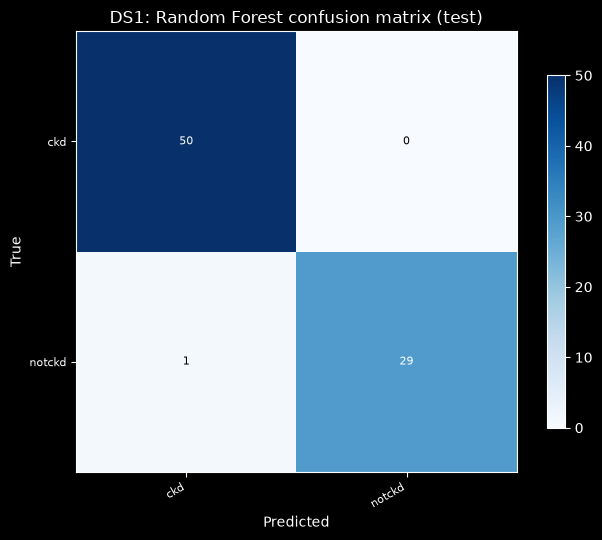

In [4]:
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=[f"{c} (true)" for c in class_order],
                     columns=[f"{c} (pred)" for c in class_order])
print(cm_df.to_string())

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(class_order)), class_order, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(class_order)), class_order, fontsize=8)
for i in range(len(class_order)):
    for j in range(len(class_order)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title(f"{ds_id}: Random Forest confusion matrix (test)")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**Observation**

The confusion matrix is mostly diagonal: all 50 ckd cases and 29 of 30 notckd cases are correct. The single false alarm (a healthy patient flagged as ckd) is the safer error direction in a screening setting; no ckd case is missed.

hemo      0.3281
sg        0.1569
rbcc      0.1313
htn       0.0806
dm        0.0652
log_bu    0.0526
bgr       0.0443
sod       0.0419
bp        0.0232
appet     0.0151
su        0.0134
pc        0.0131
pot       0.0118
wbcc      0.0117
pe        0.0110


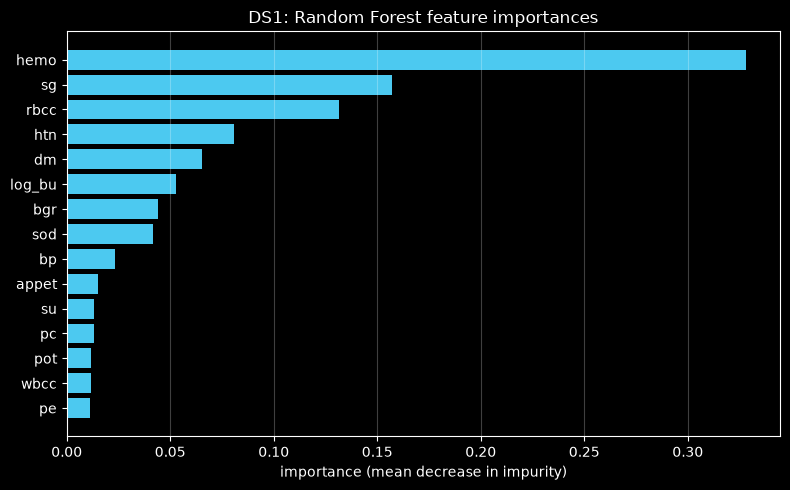

In [5]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances.round(4).to_string())

plt.style.use("dark_background")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importances.index[::-1], importances.values[::-1], color="#4cc9f0")
ax.set_title(f"{ds_id}: Random Forest feature importances")
ax.set_xlabel("importance (mean decrease in impurity)")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

**Observation**

Hemoglobin dominates the importances (0.328), followed by specific gravity (0.157) and red blood cell count (0.131) - the anaemia and urine-concentration markers that the feature-selection ranking also puts on top. Hypertension (0.081), diabetes (0.065), log blood urea (0.053) and random glucose (0.044) form the second tier; the remaining features contribute little.

### Selected features vs all features

In [6]:
all_features = [c for c in train.columns if c != target]
Xa_train, ya_train = xy(train, all_features)
Xa_test, ya_test = xy(test, all_features)

rf_all = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=config["training"]["random_state"],
    n_jobs=-1,
)
rf_all.fit(Xa_train, ya_train)
y_pred_all = rf_all.predict(Xa_test)

comparison = pd.DataFrame({
    f"selected ({len(selected)})": [accuracy_score(y_test, y_pred), f1_score(y_test, y_pred, average="macro")],
    f"all ({len(all_features)})": [accuracy_score(y_test, y_pred_all), f1_score(y_test, y_pred_all, average="macro")],
}, index=["accuracy", "macro F1"])
print(comparison.round(4).to_string())

          selected (15)  all (30)
accuracy         0.9875    0.9875
macro F1         0.9866    0.9866


**Observation**

The forest on the 15 selected features scores 0.988 / 0.987, the same as on all 30 features. The selection halves the number of features without losing performance.

**Summary:** Random Forest on DS1 reaches 0.988 accuracy and 0.987 macro F1 on the test split, with realistic and interpretable errors. This run followed the switch of the main dataset from DS3 to DS1: DS3's perfect 1.000 score exposed its constructed labels (the stage values are built from the lab features themselves), while DS1's genuine patient outcomes produce the honest baseline the coursework needs.